In [1]:
import io
import os
import pandas as pd
import paramiko
import matplotlib.pyplot as plt
df=pd.read_pickle('combined_data.pkl')

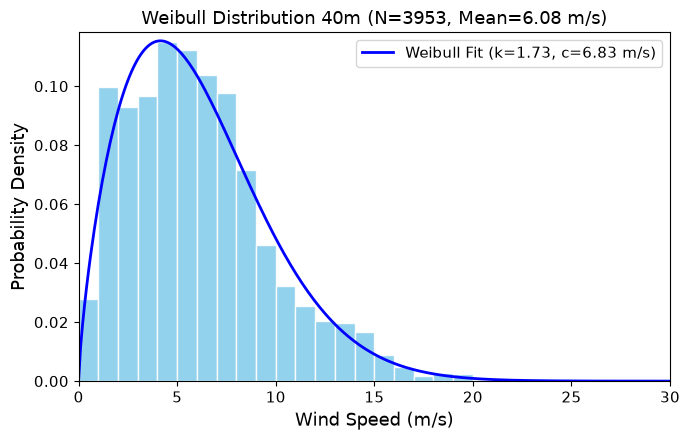

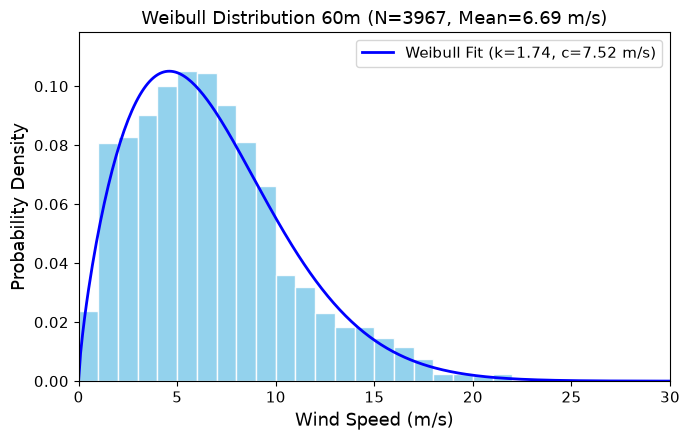

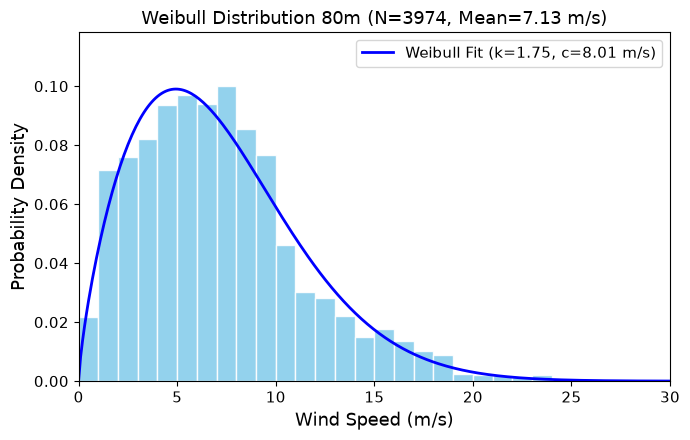

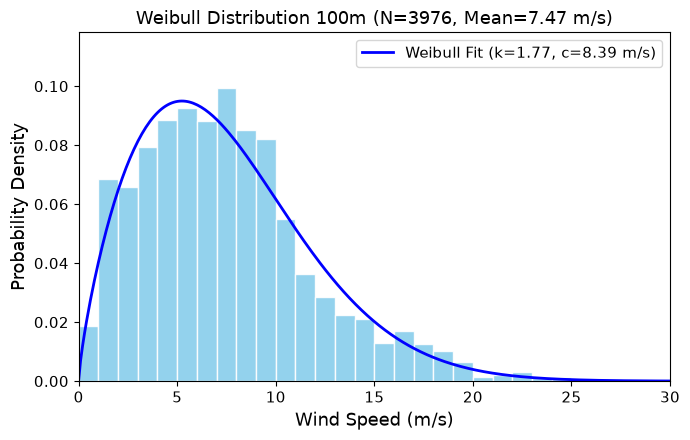

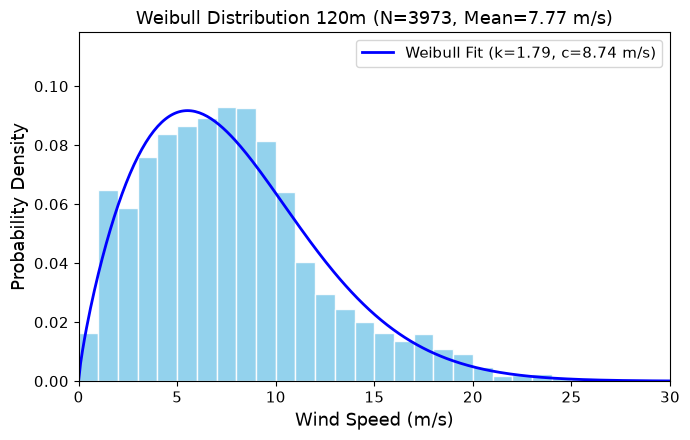

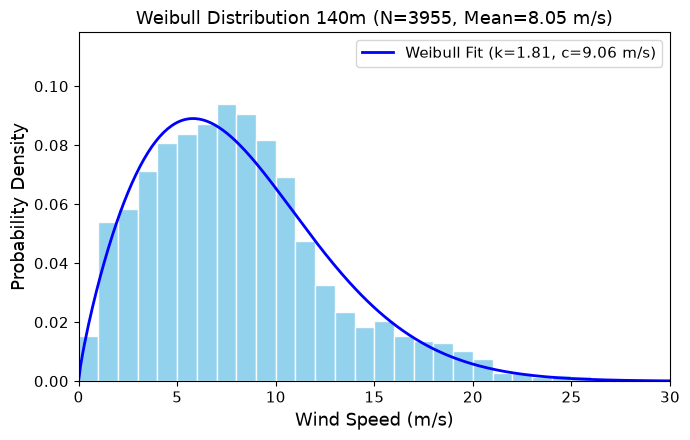

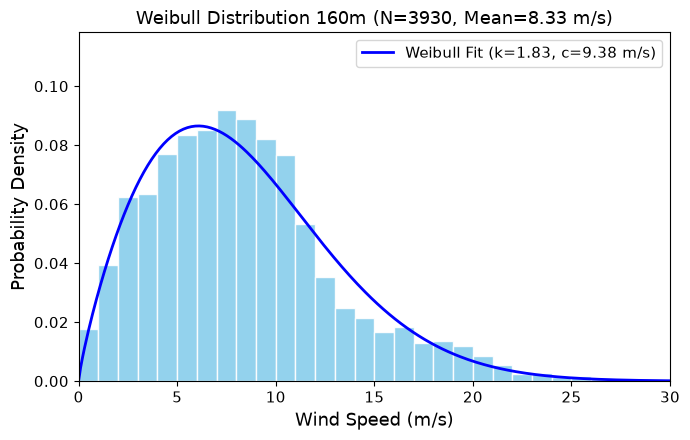

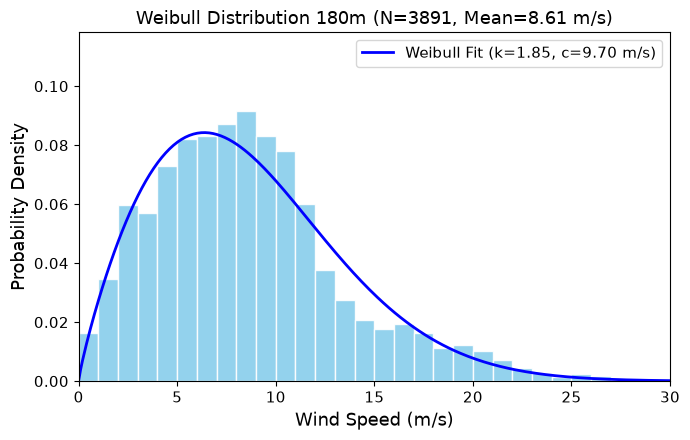

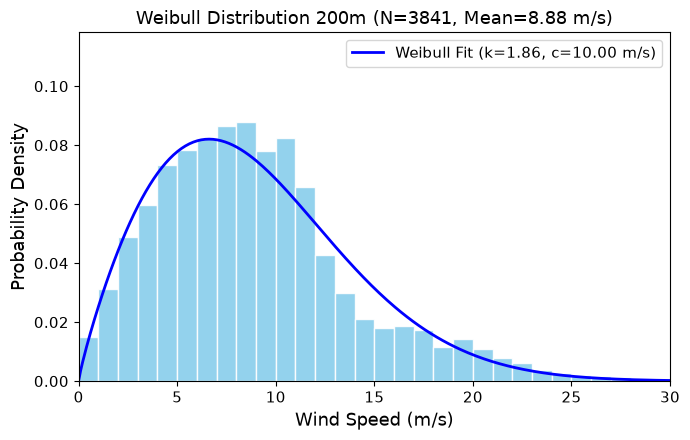

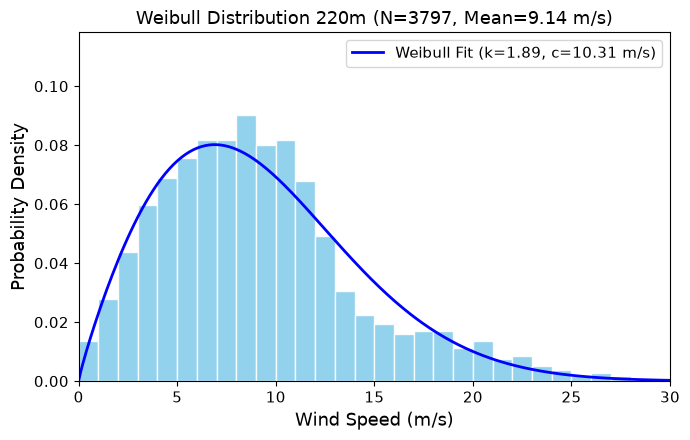

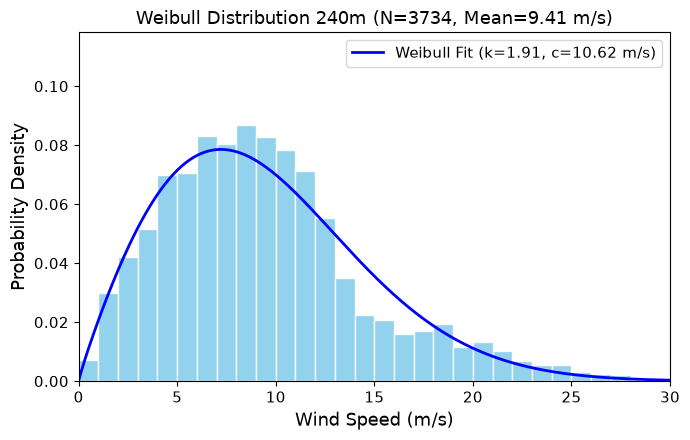

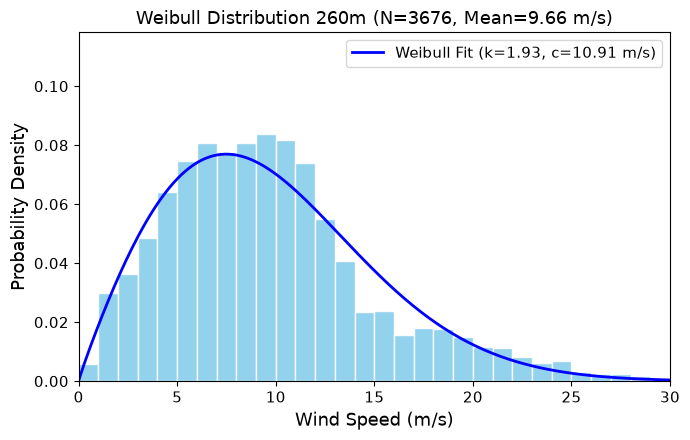

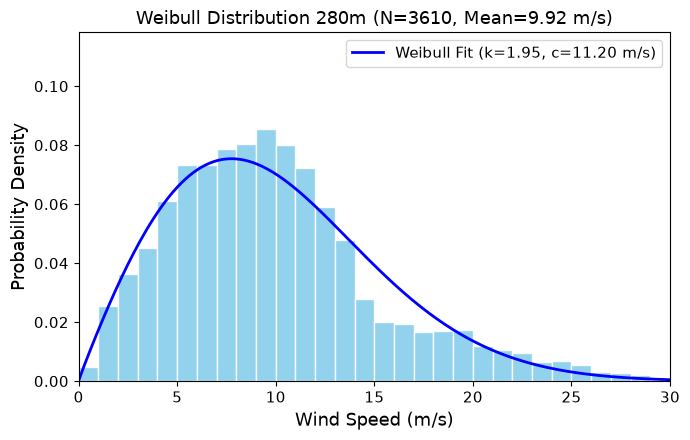

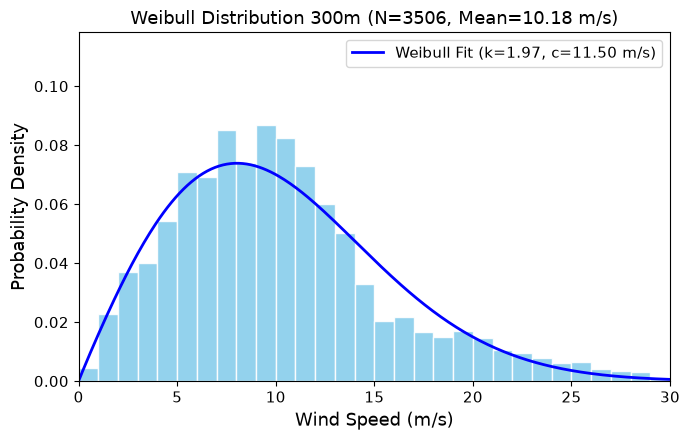

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min

# --- フォントサイズ設定 ---
TITLE_FONTSIZE = 13   # タイトルのフォントサイズ
LABEL_FONTSIZE = 13   # 軸ラベル（X軸・Y軸）のフォントサイズ
TICK_FONTSIZE = 11    # 目盛り数値のフォントサイズ
LEGEND_FONTSIZE = 11  # 凡例のフォントサイズ

# 高度リスト n = [40, 60, ..., 300]
heights = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
speed_cols = [f"{n}m Wind Speed (m/s)" for n in heights]

# 1. 全高度における風速（横軸）の最大値を取得し、1 m/s 刻みのビンを作成
max_speed = int(np.ceil(df[speed_cols].max().max()))
bins = np.arange(0, max_speed + 1, 1.0)
x = np.linspace(0, max_speed, 300)

# 2. 各高度のワイブル分布とヒストグラムを計算し、縦軸（確率密度）の全高度最大値を取得
plot_data = {}
max_density = 0.0

for n in heights:
    speed_col = f"{n}m Wind Speed (m/s)"
    speed = df[speed_col].dropna().to_numpy()
    speed_pos = speed[speed > 0]
    
    # ワイブル分布のパラメータ推定 (位置パラメータ loc=0 に固定)
    k, loc, c = weibull_min.fit(speed_pos, floc=0)
    pdf = weibull_min.pdf(x, k, loc=0, scale=c)
    
    # ヒストグラムの確率密度を計算して最大値を更新
    hist_vals, _ = np.histogram(speed, bins=bins, density=True)
    max_density = max(max_density, hist_vals.max(), pdf.max())
    
    plot_data[n] = (speed, k, c, pdf)

# 縦軸の上限（最大値に5%の余白を追加）
y_max = max_density * 1.025

# 3. 統一した横軸・縦軸の範囲で各高度をプロット
for n in heights:
    speed, k, c, pdf = plot_data[n]
    
    fig, ax = plt.subplots(figsize=(7, 4.5))
    
    # 実測ヒストグラム（確率密度）
    ax.hist(
        speed,
        bins=bins,
        density=True,
        color="skyblue",
        edgecolor="white",
        alpha=0.9,
        #label="Observed (1 m/s bin)",
    )
    
    # ワイブル分布フィット曲線
    ax.plot(
        x,
        pdf,
        color="blue",
        linewidth=2,
        label=f"Weibull Fit (k={k:.2f}, c={c:.2f} m/s)",
    )
    
    ax.set_title(
        f"Weibull Distribution {n}m (N={len(speed)}, Mean={speed.mean():.2f} m/s)",
        fontsize=TITLE_FONTSIZE,
    )
    ax.set_xlabel("Wind Speed (m/s)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Probability Density", fontsize=LABEL_FONTSIZE)
    
    # 全高度で統一した横軸・縦軸の範囲を設定
    ax.set_xlim(0, max_speed)
    ax.set_ylim(0, y_max)
    ax.set_xticks(np.arange(0, max_speed + 1, 5))
    
    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
    #ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=LEGEND_FONTSIZE)
    
    plt.tight_layout()
    plt.show()

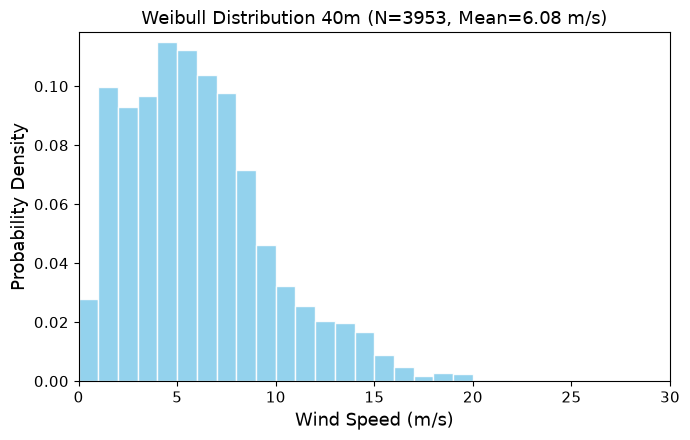

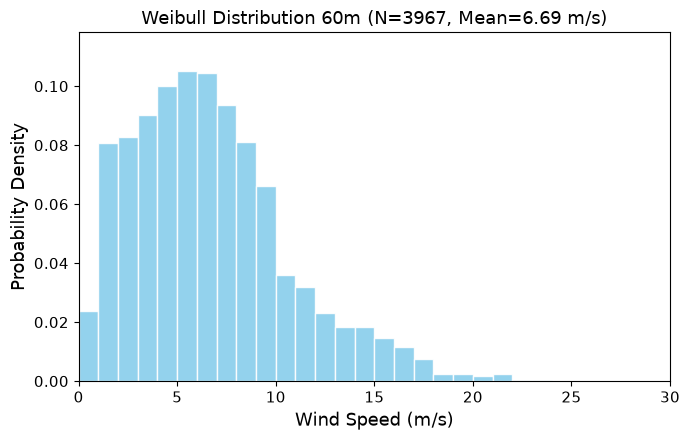

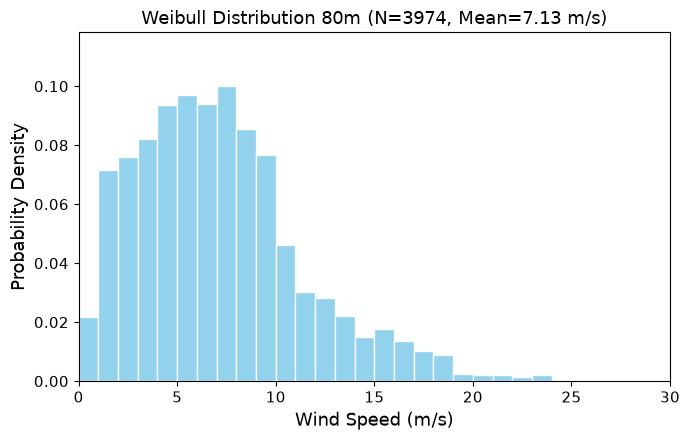

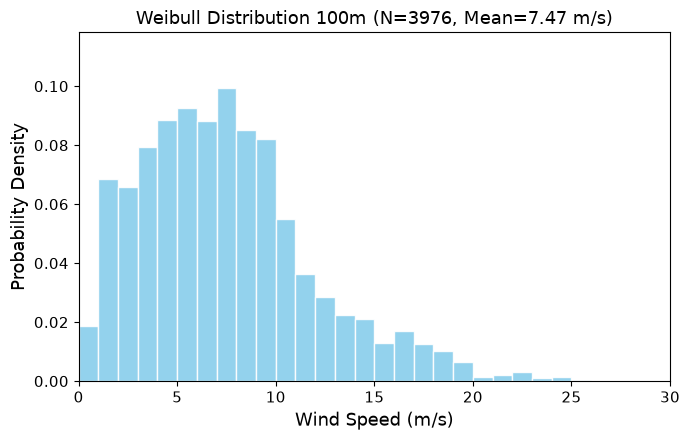

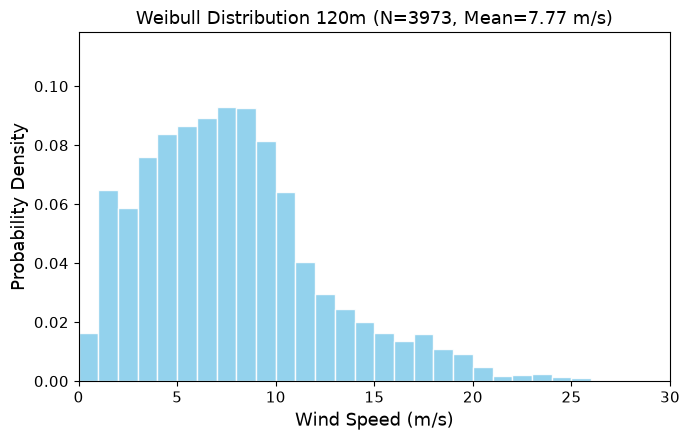

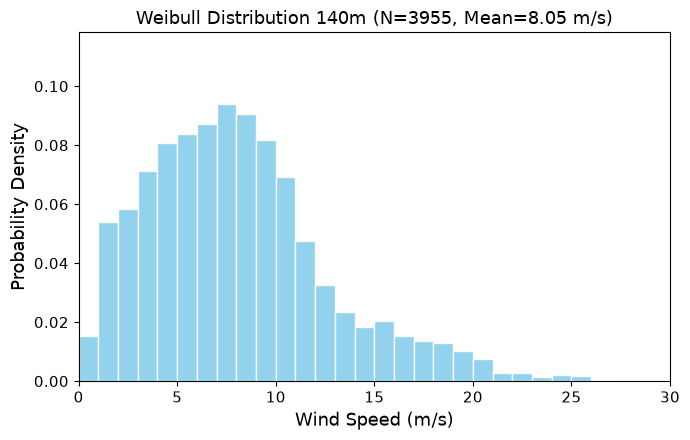

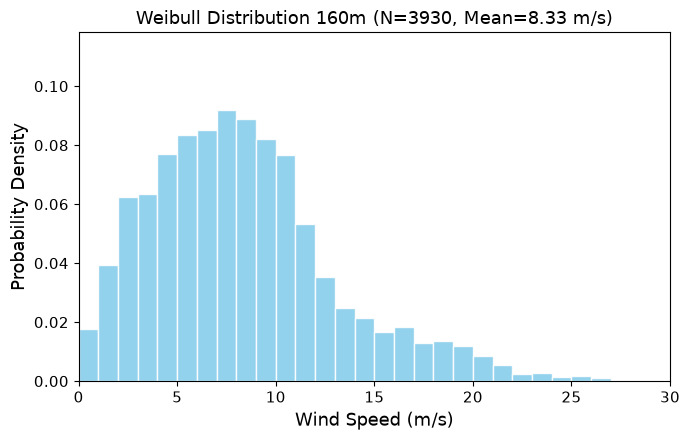

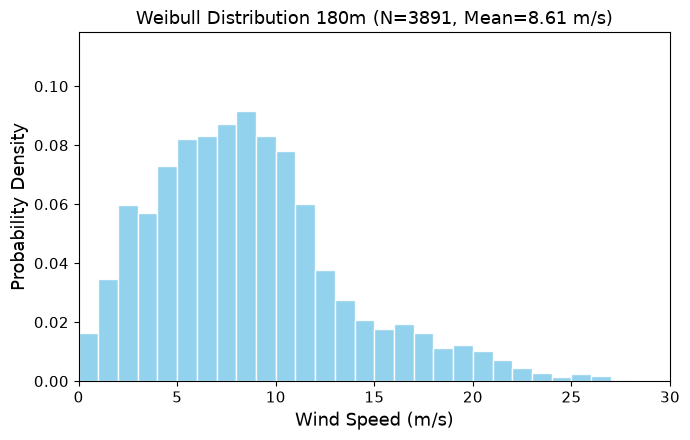

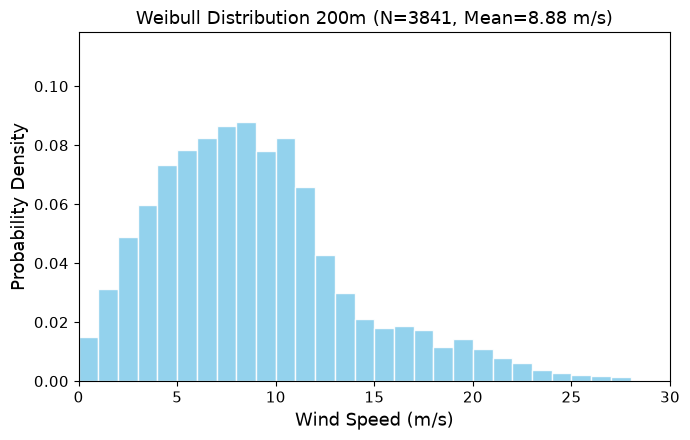

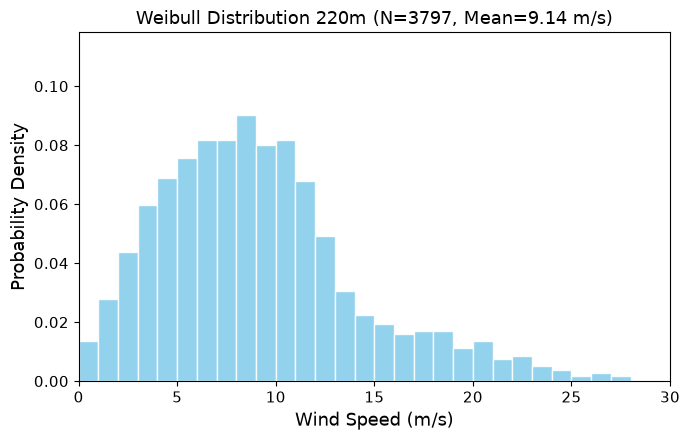

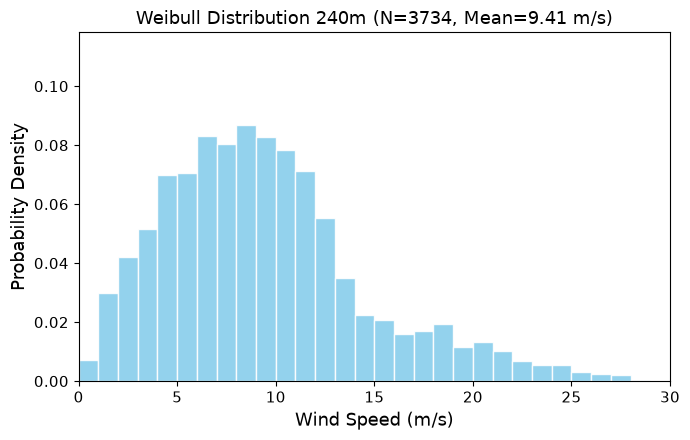

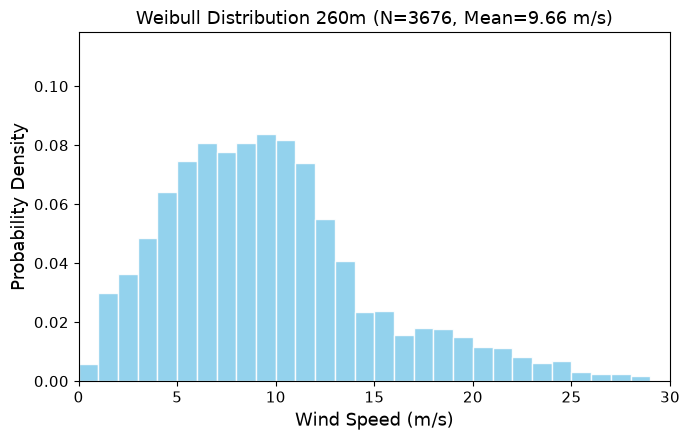

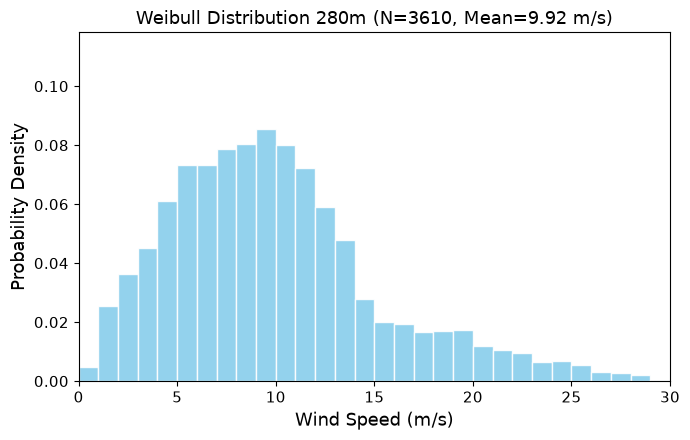

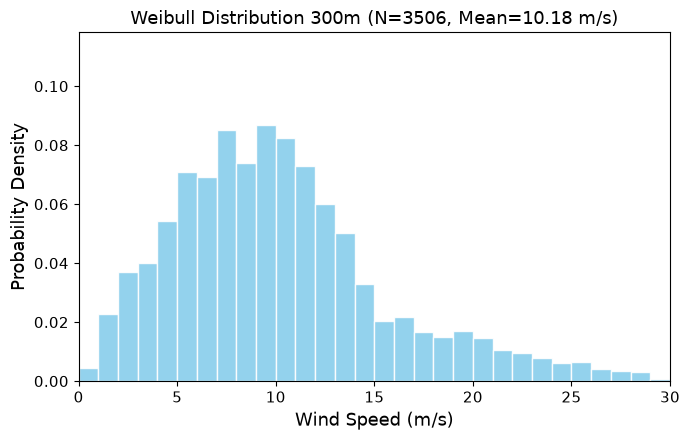

In [3]:
# ワイブル近似曲線なしのヒストグラムのみを描画
for n in heights:
    speed, k, c, pdf = plot_data[n]
    
    fig, ax = plt.subplots(figsize=(7, 4.5))
    
    # 実測ヒストグラム（確率密度）
    ax.hist(
        speed,
        bins=bins,
        density=True,
        color="skyblue",
        edgecolor="white",
        alpha=0.9,
    )
    
    ax.set_title(
        f"Weibull Distribution {n}m (N={len(speed)}, Mean={speed.mean():.2f} m/s)",
        fontsize=TITLE_FONTSIZE,
    )
    ax.set_xlabel("Wind Speed (m/s)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Probability Density", fontsize=LABEL_FONTSIZE)
    
    # 全高度で統一した横軸・縦軸の範囲を設定
    ax.set_xlim(0, max_speed)
    ax.set_ylim(0, y_max)
    ax.set_xticks(np.arange(0, max_speed + 1, 5))
    
    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
    #ax.grid(True, linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()